# M13 · Arch 3: SB-LN + feature-space private latent + linked loss

**Arch 1** (published): full LayerNorms + linear head + GBLA LN-offsets.
**Arch 2** (scratched after M12): SB-LN + private **LN** offsets ± w_g·CE.
**Arch 3** (this notebook): SB-LN + prototype head + feature-space δ_g + PFAL. Spec: `docs3/`.

| Aim | Arch 3 |
|---|---|
| 1. Not just LN + linear head | Shared **SB-LN** + **prototype head** (b, ρ) |
| 2. New loss | M1 + real-anchor + margin + **attract-to-c_fake(δ)** + λ‖δ‖² |
| 3. Private latent ↔ loss | δ_g ∈ R^d; c_fake(g)=normalize(μ_fake + W δ_g); inference δ=0 |
| 4. P < 104,450 | Deployed **34,370**; train-time **34,626** |

**Order:** §4.2 must print `M13 CHECKS OK` before §5. Pilot is resumable under `runs/m13/m13_arch3_r16_d64_…`. Delete that folder to retrain.

| Section | What | Time |
|---|---|---|
| 1–2 | setup, data | ~1–8 min |
| 3 | detector, Arch3 state | ~1 min |
| 4 | checks | ~2–5 min |
| 5 | pilot train (10 epochs) | ~1.3 h |
| 6 | FF++ / DFD / UADFV + decision vs A0 / Arch1 | ~10 min |


## 1. Setup

### 1.1 Settings

Same data paths and schedule as M4/M12. Arch3-specific: `DELTA_DIM`, `GAMMA_ATTR` (attraction to c_fake(δ)).


In [13]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
FACES_DFD = DATA_ROOT / "faces_dfd"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
FACES_UADFV = DATA_ROOT / "faces_uadfv"
UADFV_INDEX = DATA_ROOT / "index" / "uadfv.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M13_DIR = RUNS_ROOT / "m13"
M12_DIR = RUNS_ROOT / "m12"
M11A_DIR = RUNS_ROOT / "m11a"
M11B_DIR = RUNS_ROOT / "m11b"
M4_DIR = RUNS_ROOT / "m4"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0
RANK = 16
DELTA_DIM = 64          # private latent dim d (feature space)
LAMBDA = 0.01           # ||δ_g||² penalty
ALPHA_REAL = 0.1        # pull reals to c_real
BETA_MARGIN = 1.0       # fake margin off c_real
GAMMA_ATTR = 0.5        # pull fakes of g to c_fake(δ_g)  — links δ to the loss
MARGIN = 0.1
EMA = 0.99
TAU_INIT = 0.1
PROTO_WARM = 512
RUN_DFD, RUN_UADFV = True, True

A0 = {"seen": 94.54, "DF": 99.49, "F2F": 97.86, "FS": 99.60, "NT": 81.21, "FSh": 92.25, "DFD": 95.15}
REFS = {
    "full LayerNorms (M4 λ=∞)": (M4_DIR / f"gbla_laminf_{ARCH}_seed{SEED}", 96.05, 99.38),
    "GBLA λ=0.01 (M4) / Arch1": (M4_DIR / f"gbla_lam0.01_{ARCH}_seed{SEED}", 96.71, 99.63),
    "A0 SB-LN r=16 (M11a)": (M11A_DIR / f"sbln_r{RANK}_{ARCH}_seed{SEED}", None, None),
}

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "rank": RANK, "delta_dim": DELTA_DIM, "lambda": LAMBDA,
    "alpha_real": ALPHA_REAL, "beta_margin": BETA_MARGIN, "gamma_attr": GAMMA_ATTR,
    "margin": MARGIN, "ema": EMA, "tau_init": TAU_INIT, "proto_warm": PROTO_WARM,
    "private": "feature-space δ_g (training only); W fixed orthonormal; inference uses δ=0",
    "architecture": "Arch3",
    "question": "SB-LN + feature δ linked to loss: checks pass and P < 104450?",
}
assert INDEX_CSV.exists(), INDEX_CSV
assert (M11A_DIR / f"sbln_r{RANK}_{ARCH}_seed{SEED}" / "results.json").exists(), "M11a r=16 missing"
M13_DIR.mkdir(parents=True, exist_ok=True)
print("M13 runs go to:", M13_DIR)
print(f"Arch3 defaults: r={RANK}, d={DELTA_DIM}, λ={LAMBDA}")


M13 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m13
Arch3 defaults: r=16, d=64, λ=0.01


### 1.2 Imports and environment

Same as M12.


In [14]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M13 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),1020.0


## 2. Data

### 2.1 Index and subsets

Same splits as M1/M4/M12.


In [15]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))


,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Same as M12.


In [16]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")


train crops -> RAM: 100%|██████████| 115200/115200 [01:04<00:00, 1799.48it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.1 min (1700 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:03<00:00, 1709.75it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1651 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:14<00:00, 1799.07it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.3 min (1722 crops/s from disk)


### 2.3 Round-robin loader

Same as M4/M12.


In [17]:
# 2.3 Round-robin loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    """One epoch = one block per training generator, in an order fixed by (seed, epoch)."""

    def __init__(self, df, seed):
        self.seed = seed
        self.epoch = 0
        gen = df.generator.values
        real_idx = np.flatnonzero(gen == "original")
        # fixed split: real row r goes to generator r % G
        self.blocks = {}
        for k, g in enumerate(TRAIN_GENERATORS):
            fakes = np.flatnonzero(gen == g)
            reals = real_idx[k::G][: len(fakes) // G]
            self.blocks[g] = (fakes, reals)
        self.n_per = len(self.blocks[TRAIN_GENERATORS[0]][0]) + len(self.blocks[TRAIN_GENERATORS[0]][1])

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order_rng = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(TRAIN_GENERATORS)
        order_rng.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n_per * G


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = RoundRobinSampler(train_df, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
owned = {SHORT[g]: (len(f), len(r)) for g, (f, r) in train_sampler.blocks.items()}
print("fakes / reals owned by each generator:", owned)
print(f"steps per epoch: {len(train_loader)}  (M1 was 900);  workers: {NUM_WORKERS}")
assert len(train_loader) == 900, len(train_loader)


fakes / reals owned by each generator: {'DF': (23040, 5760), 'F2F': (23040, 5760), 'FS': (23040, 5760), 'NT': (23040, 5760)}
steps per epoch: 900  (M1 was 900);  workers: 7


### 2.4 Data-loading speed

Same measurement as M4.


In [18]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per ablation ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()


,value
"CPU time per augmented crop, one process (ms)",35.5
data loading speed (img/s),994
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per ablation (10 epochs),1.3


## 3. Model

### 3.1 Detector

Same CLIP encoder as M1/M4. Linear head stays in the module for `set_flat`/`THETA0` compatibility but is **not** used by Arch 3 (prototype head instead).


In [19]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450


trainable numbers P = 104,450


### 3.2 Arch 3 state

- **SB-LN:** γ = γ⁰ + A B_γᵀ, β = β⁰ + C B_βᵀ (shared).
- **Prototype head:** b, ρ (2 numbers).
- **Private latent:** δ_g ∈ R^d; W fixed orthonormal; c_fake(g) = normalize(μ_fake + W δ_g).
- **Deployed** = SB-LN + 2 (δ discarded at inference). **Train-time** adds G·d.


In [20]:
# 3.2 SB-LN + Arch3 private feature latent
WIDTH = model.encoder.transformer.width
SLICES, offset = {}, 0
for n, p in PARAMS:
    SLICES[n] = slice(offset, offset + p.numel())
    offset += p.numel()
LN_MODULES = [n[:-len(".weight")] for n in PARAM_NAMES if n.endswith(".weight") and not n.startswith("head")]
N_LN = len(LN_MODULES)
assert N_LN == 50 and WIDTH == 1024
GAMMA_IDX = torch.stack([torch.arange(SLICES[m + ".weight"].start, SLICES[m + ".weight"].stop) for m in LN_MODULES]).to(DEVICE)
BETA_IDX = torch.stack([torch.arange(SLICES[m + ".bias"].start, SLICES[m + ".bias"].stop) for m in LN_MODULES]).to(DEVICE)
HEAD_IDX = torch.cat([torch.arange(SLICES[n].start, SLICES[n].stop) for n in PARAM_NAMES if n.startswith("head")]).to(DEVICE)
G0, B0 = THETA0[GAMMA_IDX].clone(), THETA0[BETA_IDX].clone()


def sbln_numel(rank=RANK):
    return 2 * WIDTH * rank + 2 * N_LN * rank


def deployed_numel(rank=RANK):
    """Inference-time trained numbers: SB-LN + prototype (b, ρ). δ discarded."""
    return sbln_numel(rank) + 2


def train_numel(rank=RANK, d=DELTA_DIM):
    """Train-time numbers including private δ_g (not deployed)."""
    return deployed_numel(rank) + G * d


class Arch3State:
    """Shared SB-LN + prototype head + per-generator feature latent δ_g ∈ R^d.

    W is a fixed orthonormal WIDTH×d matrix (buffer, not trained).
    c_fake(g) = normalize(μ_fake + W δ_g). Inference uses δ=0.
    """

    def __init__(self, rank=RANK, d=DELTA_DIM, seed=SEED):
        self.rank, self.d = rank, d
        gen = torch.Generator().manual_seed(seed)
        scale = math.sqrt(WIDTH / rank)

        def basis():
            q, _ = torch.linalg.qr(torch.randn(WIDTH, rank, generator=gen))
            return (q * scale).to(DEVICE)

        self.p = {
            "Bg": basis(), "Bb": basis(),
            "A": torch.zeros(N_LN, rank, device=DEVICE),
            "C": torch.zeros(N_LN, rank, device=DEVICE),
            "b": torch.zeros((), device=DEVICE),
            "rho": torch.full((), math.log(TAU_INIT), device=DEVICE),
        }
        # fixed projection: first d columns of a random orthonormal matrix
        qW, _ = torch.linalg.qr(torch.randn(WIDTH, d, generator=gen))
        self.W = qW.to(DEVICE)  # not trained
        self.delta = {g: torch.zeros(d, device=DEVICE) for g in TRAIN_GENERATORS}
        self.proto = {
            "real": torch.zeros(WIDTH, device=DEVICE), "n_real": 0,
            "fake": torch.zeros(WIDTH, device=DEVICE), "n_fake": 0,  # shared fake mean
        }

    def theta(self, p=None):
        p = self.p if p is None else p
        gam, bet = G0 + p["A"] @ p["Bg"].T, B0 + p["C"] @ p["Bb"].T
        t = THETA0.clone()
        t[GAMMA_IDX], t[BETA_IDX] = gam, bet
        return t

    def sb_grads(self, grad):
        Gg, Gb, p = grad[GAMMA_IDX], grad[BETA_IDX], self.p
        return {
            "A": Gg @ p["Bg"], "Bg": Gg.T @ p["A"],
            "C": Gb @ p["Bb"], "Bb": Gb.T @ p["C"],
        }

    def c_real(self, proto=None):
        proto = self.proto if proto is None else proto
        assert proto["n_real"] > 0, "real prototype not initialised"
        return F.normalize(proto["real"], dim=0)

    def c_fake(self, g=None, delta=None, proto=None):
        """Shared fake mean, optionally shifted by W δ_g. g=None or delta=0 → shared."""
        proto = self.proto if proto is None else proto
        assert proto["n_fake"] > 0, "fake prototype not initialised"
        base = proto["fake"]
        if g is None:
            return F.normalize(base, dim=0)
        dvec = self.delta[g] if delta is None else delta
        return F.normalize(base + self.W @ dvec, dim=0)

    def head_parts(self, g=None, delta=None, proto=None):
        cr, cf = self.c_real(proto), self.c_fake(g, delta, proto)
        w = F.normalize(cf - cr, dim=0)
        mbar = (cr + cf) / 2
        return {"w": w, "mbar": mbar, "c_real": cr, "c_fake": cf}

    @torch.no_grad()
    def update_prototypes(self, z, y):
        def ema(old, new, n):
            return new.clone() if n == 0 else EMA * old + (1 - EMA) * new
        real = y == 0
        if real.any():
            self.proto["real"] = ema(self.proto["real"], z[real].mean(0), self.proto["n_real"])
            self.proto["n_real"] += 1
        if (~real).any():
            self.proto["fake"] = ema(self.proto["fake"], z[~real].mean(0), self.proto["n_fake"])
            self.proto["n_fake"] += 1

    def save(self):
        return {
            "architecture": "Arch3", "rank": self.rank, "delta_dim": self.d,
            "phi": {k: v.detach().cpu() for k, v in self.p.items()},
            "delta": {g: v.detach().cpu() for g, v in self.delta.items()},
            "W": self.W.cpu(),
            "proto": {
                "real": self.proto["real"].cpu(), "n_real": self.proto["n_real"],
                "fake": self.proto["fake"].cpu(), "n_fake": self.proto["n_fake"],
            },
            "theta": self.theta().cpu(),
        }

    def load(self, obj):
        for k, v in obj["phi"].items():
            self.p[k].copy_(v.to(DEVICE))
        for g, v in obj["delta"].items():
            self.delta[g].copy_(v.to(DEVICE))
        self.W.copy_(obj["W"].to(DEVICE))
        self.proto["real"].copy_(obj["proto"]["real"].to(DEVICE))
        self.proto["fake"].copy_(obj["proto"]["fake"].to(DEVICE))
        self.proto["n_real"] = int(obj["proto"]["n_real"])
        self.proto["n_fake"] = int(obj["proto"]["n_fake"])


report = pd.DataFrame([{
    "piece": "SB-LN (r=%d)" % RANK,
    "trainable": sbln_numel(),
    "deployed": True,
}, {
    "piece": "prototype (b, ρ)",
    "trainable": 2,
    "deployed": True,
}, {
    "piece": "private δ_g (G×d=%d×%d)" % (G, DELTA_DIM),
    "trainable": G * DELTA_DIM,
    "deployed": False,
}, {
    "piece": "W (fixed orthonormal)",
    "trainable": 0,
    "deployed": False,
}, {
    "piece": "TOTAL deployed",
    "trainable": deployed_numel(),
    "deployed": True,
}, {
    "piece": "TOTAL train-time",
    "trainable": train_numel(),
    "deployed": False,
}])
display(report)
assert deployed_numel() < 104_450
assert train_numel() < 104_450
print(f"deployed {deployed_numel():,} < 104,450; train-time {train_numel():,} < 104,450")


,piece,trainable,deployed
0,SB-LN (r=16),34368,True
1,"prototype (b, ρ)",2,True
2,private δ_g (G×d=4×64),256,False
3,W (fixed orthonormal),0,False
4,TOTAL deployed,34370,True
5,TOTAL train-time,34626,False


deployed 34,370 < 104,450; train-time 34,626 < 104,450


## 4. Checks

### 4.1 Loss, step, prediction

`arch3_loss` = M1 + α(1−cos to c_real) on reals + β relu(cos−m) on fakes + **γ(1−cos to c_fake(δ_g))** on fakes + λ‖δ_g‖². The γ term is what links the private latent to the loss.


In [21]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_m1(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def head_logit(z, b, rho, parts):
    return ((z - parts["mbar"]) @ parts["w"] - b) / rho.exp()


def arch3_loss(z, y, g, state, b, rho, delta=None, margin=MARGIN):
    """M1 + real pull + fake margin off c_real + attract fakes to c_fake(δ_g) + λ‖δ‖²."""
    dvec = state.delta[g] if delta is None else delta
    hp = state.head_parts(g, dvec)
    logits = torch.stack([torch.zeros_like(z[:, 0]), head_logit(z, b, rho, hp)], dim=1)
    base, parts, ce_each = compute_m1(logits, z, y)
    cr, cf = hp["c_real"], hp["c_fake"]
    real = y == 0
    l_real = (1 - (z[real] @ cr)).mean() if real.any() else z.new_zeros(())
    l_margin = F.relu((z[~real] @ cr) - margin).mean() if (~real).any() else z.new_zeros(())
    l_attr = (1 - (z[~real] @ cf)).mean() if (~real).any() else z.new_zeros(())
    penalty = LAMBDA * dvec.pow(2).sum()
    loss = base + ALPHA_REAL * l_real + BETA_MARGIN * l_margin + GAMMA_ATTR * l_attr + penalty
    parts.update({
        "loss": float(loss.detach()), "real": float(l_real.detach()),
        "margin": float(l_margin.detach()), "attr": float(l_attr.detach()),
        "penalty": float(penalty.detach()), "delta_norm2": float(dvec.pow(2).sum().detach()),
    })
    return loss, parts, ce_each, hp


def encode(x):
    with torch.autocast("cuda", dtype=torch.bfloat16):
        feats = model.encoder(x)
    return F.normalize(feats.float(), dim=-1)


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def adam_step(param, grad, m, v, t, lr):
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    param.addcdiv_(m / (1 - b1 ** t), (v / (1 - b2 ** t)).sqrt().add_(eps), value=-lr)


class AdamSlots:
    @staticmethod
    def tensors(state):
        out = dict(state.p)
        out.update({f"delta:{g}": d for g, d in state.delta.items()})
        return out

    def __init__(self, state):
        ts = self.tensors(state)
        self.m = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.v = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.t = {k: torch.zeros((), dtype=torch.long, device=DEVICE) for k in ts}

    def state_dict(self):
        return {"m": {k: v.cpu() for k, v in self.m.items()},
                "v": {k: v.cpu() for k, v in self.v.items()},
                "t": {k: int(v) for k, v in self.t.items()}}

    def load_state_dict(self, s):
        for k in self.m:
            self.m[k].copy_(s["m"][k].to(DEVICE))
            self.v[k].copy_(s["v"][k].to(DEVICE))
            self.t[k].fill_(s["t"][k])


def flat_grad_safe():
    return torch.cat([(p.grad if p.grad is not None else torch.zeros_like(p)).reshape(-1)
                      for _, p in PARAMS]).float()


def train_step(state, opt, x, y, g, lr):
    set_flat(state.theta())
    model.zero_grad(set_to_none=True)
    b = state.p["b"].detach().clone().requires_grad_(True)
    rho = state.p["rho"].detach().clone().requires_grad_(True)
    dvec = state.delta[g].detach().clone().requires_grad_(True)
    z = encode(x)
    loss, parts, ce_each, _ = arch3_loss(z, y, g, state, b, rho, delta=dvec)
    loss.backward()
    sb = state.sb_grads(flat_grad_safe().detach())
    grads = {
        **sb,
        "b": b.grad.detach(), "rho": rho.grad.detach(),
        f"delta:{g}": dvec.grad.detach(),
    }
    state.update_prototypes(z.detach(), y)
    tensors = AdamSlots.tensors(state)
    for k, gk in grads.items():
        adam_step(tensors[k], gk, opt.m[k], opt.v[k], opt.t[k], lr)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


def load_paths(paths, desc):
    out = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


def ram_images(name, df):
    if images.get(name) is None:
        images[name] = load_images(df, f"{name} crops -> RAM")
    return images[name]


@torch.no_grad()
def predict_probs(state, arr, desc="predict"):
    """Inference: δ=0 (shared fake centroid only)."""
    set_flat(state.theta())
    model.eval()
    hp = state.head_parts(g=None)  # δ discarded
    b, rho = state.p["b"], state.p["rho"]
    out = []
    for s in tqdm(range(0, len(arr), EVAL_BATCH), desc=desc, leave=False):
        z = encode(to_model_input(arr[s:s + EVAL_BATCH]))
        out.append(torch.sigmoid(head_logit(z, b, rho, hp)).float().cpu())
    model.train()
    return torch.cat(out).numpy()


@torch.no_grad()
def exact_prototypes(state, n_per_group=None, seed=SEED):
    arr = ram_images("train", train_df)
    set_flat(state.theta())
    model.eval()
    rng = np.random.default_rng([seed, 13])
    real_rows = np.concatenate([train_sampler.blocks[g][1] for g in TRAIN_GENERATORS])
    fake_rows = np.concatenate([train_sampler.blocks[g][0] for g in TRAIN_GENERATORS])
    proto = {"real": None, "n_real": 1, "fake": None, "n_fake": 1}
    for name, rows in [("real", real_rows), ("fake", fake_rows)]:
        if n_per_group is not None and len(rows) > n_per_group:
            rows = rng.choice(rows, n_per_group, replace=False)
        rows = np.sort(rows)
        total = torch.zeros(WIDTH, device=DEVICE)
        for s in range(0, len(rows), EVAL_BATCH):
            total += encode(to_model_input(arr[rows[s:s + EVAL_BATCH]])).sum(0)
        proto[name] = total / len(rows)
    model.train()
    return proto


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos, n_neg = labels.sum(), len(labels) - labels.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(
            label=("label", "first"), prob=("prob", "mean"))
        rows.append({"test set": name,
                     "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
                     "frame AUC": 100 * auc(sub.label, sub.prob),
                     "video AUC": 100 * auc(vid.label, vid.prob),
                     "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean())})
    return pd.DataFrame(rows).round(2)


def video_auc(index_df, probs):
    vid = index_df.assign(prob=probs).groupby("video_id", as_index=False).agg(
        label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


def frame_pred(df, probs):
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = probs
    return out


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def run_dir():
    return M13_DIR / f"m13_arch3_r{RANK}_d{DELTA_DIM}_{ARCH}_seed{SEED}"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))


### 4.2 Correctness checks (before finalising)

Must print `M13 CHECKS OK` and write `arch3_spec.json`. Checks: param budget; θ₀; δ=0 identity; δ moves c_fake; loss depends on δ; first step moves A,C,b,ρ,δ_g only; FD on those tensors (not bases) within 2%.


In [22]:
# 4.2 Correctness checks (gate before finalising Arch 3)
check_rows = pd.concat([train_df[train_df.generator == "original"].iloc[:4],
                        train_df[train_df.generator == TRAIN_GENERATORS[0]].iloc[:4]])
check_ds = FaceDataset(check_rows.reset_index(drop=True), train=False, images=None)
xs, ys = zip(*[(check_ds[i][0], check_ds[i][1]) for i in range(len(check_ds))])
check_x, check_y = torch.stack(xs).to(DEVICE), torch.stack(ys).to(DEVICE)
g0 = TRAIN_GENERATORS[0]

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

state = Arch3State()
budget_ok = deployed_numel() < 104_450 and train_numel() < 104_450
start_ok = torch.equal(state.theta(), THETA0)

set_flat(THETA0)
with torch.no_grad():
    z0 = encode(check_x)
state.update_prototypes(z0, check_y)

# δ=0 → c_fake equals shared fake (link identity)
cf0 = state.c_fake(g0)
cf_shared = state.c_fake(None)
delta0_ok = torch.allclose(cf0, cf_shared, atol=1e-6, rtol=0)

# nonzero δ moves c_fake (private latent is visible to the head/loss)
with torch.no_grad():
    state.delta[g0].normal_(0, 0.1)
cf1 = state.c_fake(g0)
delta_moves_ok = float((cf1 - cf_shared).norm()) > 1e-4
state.delta[g0].zero_()

# attraction term depends on δ: L(δ) != L(0) for a fake-containing batch
b0 = state.p["b"].detach().clone().requires_grad_(True)
rho0 = state.p["rho"].detach().clone().requires_grad_(True)
set_flat(state.theta())
z_chk = F.normalize(model.encoder(check_x).float(), dim=-1)
loss_at0, _, _, _ = arch3_loss(z_chk, check_y, g0, state, b0, rho0, delta=torch.zeros(DELTA_DIM, device=DEVICE))
d_rand = torch.randn(DELTA_DIM, device=DEVICE) * 0.2
loss_atd, _, _, _ = arch3_loss(z_chk, check_y, g0, state, b0, rho0, delta=d_rand)
loss_depends_ok = abs(float(loss_atd - loss_at0)) > 1e-6

# one Adam step
opt = AdamSlots(state)
before = {k: v.clone() for k, v in AdamSlots.tensors(state).items()}
train_step(state, opt, check_x, check_y, g0, LR_MAX)
after = AdamSlots.tensors(state)
moved = {k: float((before[k] - after[k]).abs().max()) > 0 for k in before}
expect = ["A", "C", "b", "rho", f"delta:{g0}"]
step_ok = all(moved[k] for k in expect)
others_ok = all(not moved[f"delta:{g}"] for g in TRAIN_GENERATORS if g != g0)
bases_still = not (moved["Bg"] or moved["Bb"])

# finite differences on A, C, b, rho, delta — not Bg/Bb (same rationale as M12)
model.eval()
state = Arch3State()
set_flat(THETA0)
with torch.no_grad():
    state.update_prototypes(z0, check_y)
    state.p["A"].normal_(0, 1e-3)
    state.p["C"].normal_(0, 1e-3)
    state.delta[g0].normal_(0, 1e-3)
base_p = {k: state.p[k].clone() for k in state.p}
base_d = state.delta[g0].clone()
fd_keys = ["A", "C", "b", "rho"]
torch.manual_seed(0)
direction = {}
for k in fd_keys:
    r = torch.randn_like(base_p[k])
    direction[k] = r / (r.norm() + 1e-12)
r = torch.randn_like(base_d)
direction["delta"] = r / (r.norm() + 1e-12)
norm = math.sqrt(sum(float(v.pow(2).sum()) for v in direction.values()))
direction = {k: v / norm for k, v in direction.items()}


def full_loss(p, dvec, need_grad):
    set_flat(state.theta(p=p))
    model.zero_grad(set_to_none=True)
    b = p["b"].clone().requires_grad_(need_grad)
    rho = p["rho"].clone().requires_grad_(need_grad)
    d_ = dvec.clone().requires_grad_(need_grad)
    z = F.normalize(model.encoder(check_x).float(), dim=-1)
    # freeze proto buffers for FD; head_parts reads state.proto + d_
    loss, _, _, _ = arch3_loss(z, check_y, g0, state, b, rho, delta=d_)
    return loss, {"b": b, "rho": rho, "delta": d_}


loss, extras = full_loss(base_p, base_d, True)
loss.backward()
sb = state.sb_grads(flat_grad_safe().detach())
grads = {**sb, "b": extras["b"].grad, "rho": extras["rho"].grad, "delta": extras["delta"].grad}
auto = sum(float((grads[k] * direction[k]).sum()) for k in direction)


def loss_at(shift):
    p = {k: base_p[k] + (shift * direction[k] if k in direction else 0) for k in base_p}
    dvec = base_d + shift * direction["delta"]
    with torch.no_grad():
        value, _ = full_loss(p, dvec, False)
    return value.item()


fd_rows = []
for eps in (1e-2, 3e-3, 1e-3, 3e-4):
    fd = (loss_at(eps) - loss_at(-eps)) / (2 * eps)
    fd_rows.append({"eps": eps, "fd": fd, "auto": auto,
                    "rel": abs(fd - auto) / max(abs(fd), abs(auto), 1e-12)})
fd_table = pd.DataFrame(fd_rows)
best_rel = float(fd_table["rel"].min())

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
model.train()

checks = {
    "deployed and train-time P < 104450": bool(budget_ok),
    "start theta = THETA0": bool(start_ok),
    "delta=0 => c_fake = shared": bool(delta0_ok),
    "nonzero delta moves c_fake": bool(delta_moves_ok),
    "loss depends on delta": bool(loss_depends_ok),
    "step moves A,C,b,rho,delta_g": bool(step_ok),
    "other deltas stay 0": bool(others_ok),
    "bases unchanged after step 1": bool(bases_still),
    "finite differences agree": best_rel < 0.02,
}
display(pd.Series(checks, name="value").to_frame())
display(fd_table.round(6))
print("deployed", deployed_numel(), "| train-time", train_numel(), "| best_rel", round(best_rel, 6))
print("moved (expect):", {k: moved[k] for k in expect})

failed = [k for k, v in checks.items() if not v]
assert not failed, "failed checks: " + ", ".join(failed)
print("M13 CHECKS OK")

# freeze architecture spec only after checks pass
spec = {
    "architecture": "Arch3",
    "status": "checks_passed",
    "definition": {
        "encoder": "CLIP ViT-L/14, LN via SB-LN (shared bases + coefficients)",
        "head": "real-anchored prototype (b, ρ); inference uses δ=0",
        "private_latent": "δ_g ∈ R^d in feature space; c_fake(g)=normalize(μ_fake + W δ_g); W fixed",
        "loss": "CE+align+uniform + α(1-cos real) + β relu(cos-m) + γ(1-cos to c_fake) + λ||δ||²",
        "rank": RANK, "delta_dim": DELTA_DIM, "lambda": LAMBDA,
        "alpha_real": ALPHA_REAL, "beta_margin": BETA_MARGIN, "gamma_attr": GAMMA_ATTR,
        "margin": MARGIN, "deployed_numel": deployed_numel(), "train_numel": train_numel(),
    },
    "checks": checks,
    "best_rel": best_rel,
    "decision_rule_for_later_train": {
        "keep_if": "NT >= A0 (81.21) and DFD >= 95.5; report FSh vs A0/Arch1",
        "else": "negative result; Arch1 remains the only main model",
    },
}
(M13_DIR / "arch3_spec.json").write_text(json.dumps(spec, indent=2))
print("wrote", M13_DIR / "arch3_spec.json")
torch.cuda.empty_cache()


,value
deployed and train-time P < 104450,True
start theta = THETA0,True
delta=0 => c_fake = shared,True
nonzero delta moves c_fake,True
loss depends on delta,True
"step moves A,C,b,rho,delta_g",True
other deltas stay 0,True
bases unchanged after step 1,True
finite differences agree,True


,eps,fd,auto,rel
0,0.0100,0.040995,0.040954,0.001016
1,0.0030,0.040978,0.040954,0.000598
2,0.0010,0.040963,0.040954,0.000234
3,0.0003,0.040059,0.040954,0.021840


deployed 34370 | train-time 34626 | best_rel 0.000234
moved (expect): {'A': True, 'C': True, 'b': True, 'rho': True, 'delta:Deepfakes': True}
M13 CHECKS OK
wrote /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m13/arch3_spec.json


## 5. Pilot training

### 5.1 Resumable train + test

One run: \(r=16\), \(d=64\), seed 0, 10 epochs. Warm-start prototypes from `PROTO_WARM` crops, then EMA. After epoch 10: exact prototype refresh, FF++ test, DFD, UADFV. Resume from `last.pt`; delete the run folder to redo.


In [23]:
# 5.1 Pilot train (resumable)
def train_arch3():
    rd = run_dir()
    rd.mkdir(parents=True, exist_ok=True)
    check_config(rd, {**COMMON_CONFIG,
                      "deployed_trainable": deployed_numel(),
                      "train_trainable": train_numel()})
    state = Arch3State()
    opt = AdamSlots(state)
    history, start_epoch = [], 0
    if (rd / "last.pt").exists():
        ckpt = load(rd / "last.pt")
        state.load(ckpt["state"])
        opt = AdamSlots(state)
        opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
        print(f"resumed from epoch {start_epoch}")
    else:
        warm = exact_prototypes(state, n_per_group=PROTO_WARM)
        state.proto = warm
        print(f"warm prototypes from {PROTO_WARM} crops / group")

    print(f"\n===== Arch3 r={RANK} d={DELTA_DIM} "
          f"(deployed {deployed_numel():,}, train-time {train_numel():,}): "
          f"{start_epoch}/{EPOCHS} =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"Arch3 ep {epoch + 1}/{EPOCHS}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            fake_codes = gen[gen != GEN_CODE["original"]]
            assert len(fake_codes) > 0 and torch.all(fake_codes == fake_codes[0]), "mixed-generator batch"
            g = CATEGORIES[int(fake_codes[0])]
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, ce_each = train_step(state, opt, x, y, g, lr)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        val_probs = predict_probs(state, ram_images("val", val_df), desc="val")
        val_table = metrics_table(frame_pred(val_df, val_probs))
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k])
                    for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({f"|d| {SHORT[g]}": float(state.delta[g].norm()) for g in TRAIN_GENERATORS})
        row.update({"b": float(state.p["b"]), "tau": float(state.p["rho"].exp()),
                    "val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state.save(), rd / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "state": state.save(), "adam": opt.state_dict(), "history": history},
                    rd / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (rd / "results.json").exists():
        if (rd / "final.pt").exists():
            final = load(rd / "final.pt")
            deployed_proto = {
                "real": final["proto"]["real"].to(DEVICE), "n_real": 1,
                "fake": final["proto"]["fake"].to(DEVICE), "n_fake": 1,
            }
        else:
            deployed_proto = exact_prototypes(state)
            save_atomic({
                "architecture": "Arch3", "rank": RANK, "delta_dim": DELTA_DIM,
                "phi": {k: v.detach().cpu() for k, v in state.p.items()},
                "W": state.W.cpu(),
                "proto": {"real": deployed_proto["real"].cpu(), "n_real": 1,
                          "fake": deployed_proto["fake"].cpu(), "n_fake": 1},
                "theta": state.theta().cpu(),
                "delta_norms": {g: float(state.delta[g].norm()) for g in TRAIN_GENERATORS},
            }, rd / "final.pt")

        # evaluate with exact-refreshed shared prototypes (δ discarded inside predict_probs)
        state.proto = deployed_proto
        test_arr = ram_images("test", test_df)
        table = metrics_table(frame_pred(test_df, predict_probs(state, test_arr, desc="test")))
        display(table)
        res = {
            "architecture": "Arch3", "rank": RANK, "delta_dim": DELTA_DIM,
            "deployed_trainable": deployed_numel(), "train_trainable": train_numel(),
            "test": table.to_dict(orient="records"), "history": history,
            "delta_norms": {SHORT[g]: float(state.delta[g].norm()) for g in TRAIN_GENERATORS},
            "b": float(state.p["b"]), "tau": float(state.p["rho"].exp()),
        }
        for name, flag, index_path, root in [("dfd", RUN_DFD, DFD_INDEX, FACES_DFD),
                                             ("uadfv", RUN_UADFV, UADFV_INDEX, FACES_UADFV)]:
            if not flag:
                continue
            idx = pd.read_csv(index_path, dtype={"video_id": str})
            arr = load_paths([root / p for p in idx.path], f"{name} crops -> RAM")
            res[f"{name}_video_auc"] = video_auc(idx, predict_probs(state, arr, desc=name))
            del arr
            print(f"{name.upper()} video AUC: {res[name + '_video_auc']:.2f}")
        (rd / "results.json").write_text(json.dumps(res, indent=1))
        print("wrote", rd / "results.json")
    else:
        print("results.json already present; skip eval")
    del state, opt
    torch.cuda.empty_cache()


train_arch3()
print("Arch3 pilot finished")


resumed from epoch 10

===== Arch3 r=16 d=64 (deployed 34,370, train-time 34,626): 10/10 =====
results.json already present; skip eval
Arch3 pilot finished


## 6. Evaluation and decision

### 6.1 Table vs A0 / Arch1 / M11b

Pre-registered rule (`docs3/arch3_decision_rule.md`): **KEEP** iff NT ≥ A0 (81.21) and DFD ≥ 95.5; else **REJECT** and Arch 1 stays the only main model.


,trainable,seen,DF,F2F,FS,NT,FSh,DFD,UADFV
model,,,,,,,,,
A0 SB-LN r=16 + linear (M11a),36418,94.54,99.49,97.86,99.60,81.21,92.25,95.15,NaN
full LayerNorms (M4 λ=∞),104450,96.41,99.72,98.66,99.34,87.90,90.53,96.05,99.38
GBLA λ=0.01 (M4) / Arch1,104450,95.55,99.43,98.55,99.17,85.06,92.91,96.71,99.63
M11b r=16 (scratched family),34370,93.66,99.56,97.77,99.41,77.91,93.01,95.56,99.46
Arch3 (this run),34370,93.74,99.22,97.67,99.64,78.42,92.83,95.46,98.50



Arch3 NT=78.42 (need >= 81.21: False)
Arch3 DFD=95.46 (need >= 95.5: False)
DECISION: REJECT Arch3 — Arch1 remains the only main model
Δ vs A0: {'seen': -0.8, 'NT': -2.79, 'FSh': 0.58, 'DFD': 0.31}
|δ| norms: {'DF': 0.01255874428898096, 'F2F': 0.028859952464699745, 'FS': 0.02767452970147133, 'NT': 0.15495598316192627}
wrote /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m13/decision.json


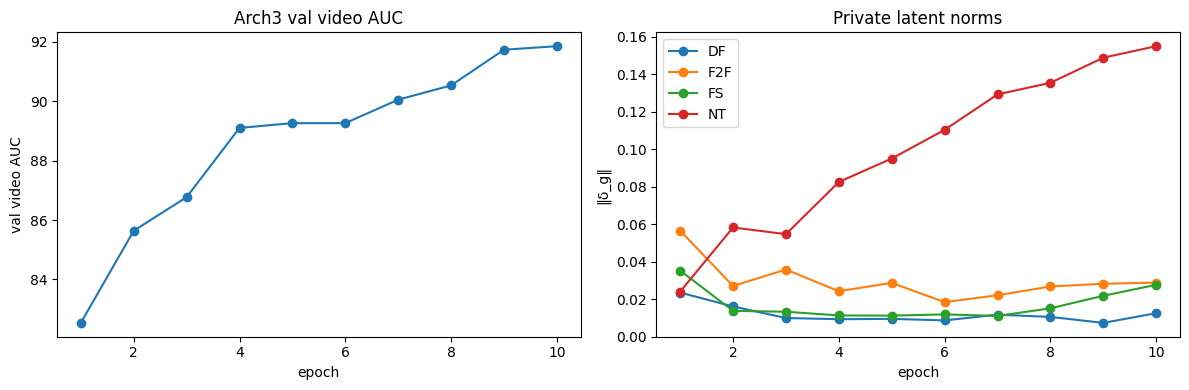

In [24]:
# 6.1 Main table + decision
def video_auc_from_records(records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"seen": float(t.iloc[0]["video AUC"])}
    row.update({SHORT[g]: float(t.loc[g, "video AUC"]) for g in ALL_GENERATORS})
    return row


rows = []
rows.append({"model": "A0 SB-LN r=16 + linear (M11a)", "trainable": 36418, **A0, "UADFV": float("nan")})

for name, (folder, dfd, uadfv) in REFS.items():
    if name.startswith("A0"):
        continue
    if not (folder / "results.json").exists():
        print("missing:", name)
        continue
    res = json.loads((folder / "results.json").read_text())
    row = {"model": name, "trainable": res.get("deployed_trainable", P),
           **video_auc_from_records(res["test"])}
    row["DFD"] = res.get("dfd_video_auc", dfd if dfd is not None else float("nan"))
    row["UADFV"] = res.get("uadfv_video_auc", uadfv if uadfv is not None else float("nan"))
    rows.append(row)

# M11b if present
m11b_path = M11B_DIR / f"m11b_r{RANK}_{ARCH}_seed{SEED}" / "results.json"
if m11b_path.exists():
    res = json.loads(m11b_path.read_text())
    rows.append({"model": "M11b r=16 (scratched family)", "trainable": res.get("deployed_trainable", 34370),
                 **video_auc_from_records(res["test"]),
                 "DFD": res.get("dfd_video_auc", float("nan")),
                 "UADFV": res.get("uadfv_video_auc", float("nan"))})

rd = run_dir()
arch3_path = rd / "results.json"
assert arch3_path.exists(), f"run pilot first: {arch3_path}"
res = json.loads(arch3_path.read_text())
arch3_row = {"model": "Arch3 (this run)", "trainable": res["deployed_trainable"],
             **video_auc_from_records(res["test"]),
             "DFD": res.get("dfd_video_auc", float("nan")),
             "UADFV": res.get("uadfv_video_auc", float("nan"))}
rows.append(arch3_row)
main_table = pd.DataFrame(rows).set_index("model")
display(main_table.round(2))
main_table.to_csv(M13_DIR / "main_table.csv")

# pre-registered decision (docs3/arch3_decision_rule.md)
nt = float(arch3_row["NT"])
dfd = float(arch3_row["DFD"])
keep_nt = nt >= A0["NT"]
keep_dfd = dfd >= 95.5
keep = keep_nt and keep_dfd
print(f"\nArch3 NT={nt:.2f} (need >= {A0['NT']}: {keep_nt})")
print(f"Arch3 DFD={dfd:.2f} (need >= 95.5: {keep_dfd})")
print("DECISION:", "KEEP Arch3 as candidate second architecture" if keep else "REJECT Arch3 — Arch1 remains the only main model")

delta = {k: round(float(arch3_row[k]) - A0[k], 2) for k in ("seen", "NT", "FSh", "DFD")}
print("Δ vs A0:", delta)
print("|δ| norms:", res.get("delta_norms"))

decision = {
    "architecture": "Arch3",
    "keep": keep,
    "criteria": {"NT_ge_A0": keep_nt, "DFD_ge_95.5": keep_dfd},
    "arch3": {k: arch3_row[k] for k in ("seen", "NT", "FSh", "DFD", "UADFV", "trainable")},
    "delta_vs_A0": delta,
    "rule": "keep iff NT >= A0 (81.21) and DFD >= 95.5",
}
(M13_DIR / "decision.json").write_text(json.dumps(decision, indent=2))
print("wrote", M13_DIR / "decision.json")

# curves
hist = pd.DataFrame(res["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["val video AUC"], marker="o")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("val video AUC"); axes[0].set_title("Arch3 val video AUC")
for g in TRAIN_GENERATORS:
    col = f"|d| {SHORT[g]}"
    if col in hist.columns:
        axes[1].plot(hist["epoch"], hist[col], marker="o", label=SHORT[g])
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("‖δ_g‖"); axes[1].set_title("Private latent norms")
axes[1].legend()
fig.tight_layout()
plt.show()
